In [1]:
# 1 - import
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
# 2 - load data
df = pd.read_csv("FINAL_USO.csv")

In [3]:
# 3 - inspect data
display(df.head())

,Date,Open,High,Low,Close,Adj Close,Volume,SP_open,SP_high,SP_low,...,GDX_Low,GDX_Close,GDX_Adj Close,GDX_Volume,USO_Open,USO_High,USO_Low,USO_Close,USO_Adj Close,USO_Volume
0,2011-12-15,154.740005,154.949997,151.710007,152.330002,152.330002,21521900,123.029999,123.199997,121.989998,...,51.570000,51.680000,48.973877,20605600,36.900002,36.939999,36.049999,36.130001,36.130001,12616700
1,2011-12-16,154.309998,155.369995,153.899994,155.229996,155.229996,18124300,122.230003,122.949997,121.300003,...,52.040001,52.680000,49.921513,16285400,36.180000,36.500000,35.730000,36.270000,36.270000,12578800
2,2011-12-19,155.479996,155.860001,154.360001,154.869995,154.869995,12547200,122.059998,122.320000,120.029999,...,51.029999,51.169998,48.490578,15120200,36.389999,36.450001,35.930000,36.200001,36.200001,7418200
3,2011-12-20,156.820007,157.429993,156.580002,156.979996,156.979996,9136300,122.180000,124.139999,120.370003,...,52.369999,52.990002,50.215282,11644900,37.299999,37.610001,37.220001,37.560001,37.560001,10041600
4,2011-12-21,156.979996,157.529999,156.130005,157.160004,157.160004,11996100,123.930000,124.360001,122.750000,...,52.419998,52.959999,50.186852,8724300,37.669998,38.240002,37.520000,38.110001,38.110001,10728000


In [4]:
# 4 - data overview
print("Shape:", df.shape)
df.info()

Shape: (1718, 81)
<class 'pandas.DataFrame'>
RangeIndex: 1718 entries, 0 to 1717
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           1718 non-null   str    
 1   Open           1718 non-null   float64
 2   High           1718 non-null   float64
 3   Low            1718 non-null   float64
 4   Close          1718 non-null   float64
 5   Adj Close      1718 non-null   float64
 6   Volume         1718 non-null   int64  
 7   SP_open        1718 non-null   float64
 8   SP_high        1718 non-null   float64
 9   SP_low         1718 non-null   float64
 10  SP_close       1718 non-null   float64
 11  SP_Ajclose     1718 non-null   float64
 12  SP_volume      1718 non-null   int64  
 13  DJ_open        1718 non-null   float64
 14  DJ_high        1718 non-null   float64
 15  DJ_low         1718 non-null   float64
 16  DJ_close       1718 non-null   float64
 17  DJ_Ajclose     1718 non-null   float64
 18  D

In [5]:
# 5 - check data
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Date             0
Open             0
High             0
Low              0
Close            0
                ..
USO_High         0
USO_Low          0
USO_Close        0
USO_Adj Close    0
USO_Volume       0
Length: 81, dtype: int64
Duplicate rows: 0


In [6]:
# 6 - statistics
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,1718,1718,2011-12-15,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Open,1718.0,NaN,NaN,NaN,127.323434,17.526993,100.919998,116.220001,121.915001,128.427494,173.199997
High,1718.0,NaN,NaN,NaN,127.854237,17.631189,100.989998,116.540001,122.325001,129.087498,174.070007
Low,1718.0,NaN,NaN,NaN,126.777695,17.396513,100.230003,115.739998,121.369999,127.840001,172.919998
Close,1718.0,NaN,NaN,NaN,127.319482,17.536269,100.5,116.052502,121.795002,128.470001,173.610001
...,...,...,...,...,...,...,...,...,...,...,...
USO_High,1718.0,NaN,NaN,NaN,22.307148,11.478671,8.03,11.5,16.635001,34.667499,42.299999
USO_Low,1718.0,NaN,NaN,NaN,21.904657,11.373997,7.67,11.3,16.04,34.11,41.299999
USO_Close,1718.0,NaN,NaN,NaN,22.109051,11.432787,7.96,11.3925,16.345,34.417499,42.009998
USO_Adj Close,1718.0,NaN,NaN,NaN,22.109051,11.432787,7.96,11.3925,16.345,34.417499,42.009998


In [7]:
# 7 - preprocess
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
numeric_cols = df.columns.drop("Date")
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")
df = df.dropna(subset=["Date", "Close"]).drop_duplicates()
df = df.sort_values("Date").reset_index(drop=True)

In [8]:
# 8 - create documents
documents = [
    "Market data on " + r["Date"].strftime("%Y-%m-%d") + ": " +
    ", ".join(f"{col} {r[col]}" for col in df.columns if col != "Date" and pd.notna(r[col])) + "."
    for _, r in df.iterrows()
]
print(documents[:3])

['Market data on 2011-12-15: Open 154.740005, High 154.949997, Low 151.71000700000005, Close 152.330002, Adj Close 152.330002, Volume 21521900, SP_open 123.029999, SP_high 123.199997, SP_low 121.989998, SP_close 122.18, SP_Ajclose 105.44123799999998, SP_volume 199109200, DJ_open 11825.29004, DJ_high 11967.83984, DJ_low 11825.21973, DJ_close 11868.80957, DJ_Ajclose 11868.80957, DJ_volume 136930000, EG_open 74.550003, EG_high 76.150002, EG_low 72.150002, EG_close 72.900002, EG_Ajclose 70.43175500000002, EG_volume 787900, EU_Price 1.3018, EU_open 1.2982, EU_high 1.3051, EU_low 1.2957, EU_Trend 1, OF_Price 105.09, OF_Open 104.88, OF_High 106.5, OF_Low 104.88, OF_Volume 14330, OF_Trend 1, OS_Price 93.42, OS_Open 94.91, OS_High 96.0, OS_Low 93.33, OS_Trend 0, SF_Price 53604, SF_Open 54248, SF_High 54248, SF_Low 52316, SF_Volume 119440, SF_Trend 1, USB_Price 1.911, USB_Open 1.911, USB_High 1.911, USB_Low 1.911, USB_Trend 1, PLT_Price 1414.65, PLT_Open 1420.3, PLT_High 1423.35, PLT_Low 1376.85

In [9]:
# 9 - create knowledge base
knowledge_base = pd.DataFrame({
    "record_id": range(len(df)),
    "document": documents
})
display(knowledge_base.head())

,record_id,document
0,0,"Market data on 2011-12-15: Open 154.740005, Hi..."
1,1,"Market data on 2011-12-16: Open 154.309998, Hi..."
2,2,"Market data on 2011-12-19: Open 155.479996, Hi..."
3,3,"Market data on 2011-12-20: Open 156.820007, Hi..."
4,4,"Market data on 2011-12-21: Open 156.979996, Hi..."


In [10]:
# 10 - create triples
triples = []
for i, row in df.iterrows():
    entity = f"MarketDay_{i}"
    triples.append((entity, "has_date", row["Date"].strftime("%Y-%m-%d")))
    for col in df.columns:
        if col != "Date" and pd.notna(row[col]):
            triples.append((entity, f"has_{col.lower().replace(' ', '_')}", str(row[col])))
print(triples[:10])

[('MarketDay_0', 'has_date', '2011-12-15'), ('MarketDay_0', 'has_open', '154.740005'), ('MarketDay_0', 'has_high', '154.949997'), ('MarketDay_0', 'has_low', '151.71000700000005'), ('MarketDay_0', 'has_close', '152.330002'), ('MarketDay_0', 'has_adj_close', '152.330002'), ('MarketDay_0', 'has_volume', '21521900'), ('MarketDay_0', 'has_sp_open', '123.029999'), ('MarketDay_0', 'has_sp_high', '123.199997'), ('MarketDay_0', 'has_sp_low', '121.989998')]


In [11]:
# 11 - build knowledge graph
G = nx.DiGraph()
for subject, relation, obj in triples:
    G.add_edge(subject, obj, relation=relation)
print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())

Nodes: 67727 | Edges: 119264


In [12]:
# 12 - graph query
def get_gold_close_by_date(date):
    return [
        obj for subject, relation, obj in triples
        if relation == "has_close"
        and any(s == subject and r == "has_date" and o == date for s, r, o in triples)
    ]

get_gold_close_by_date("2024-01-01")

[]

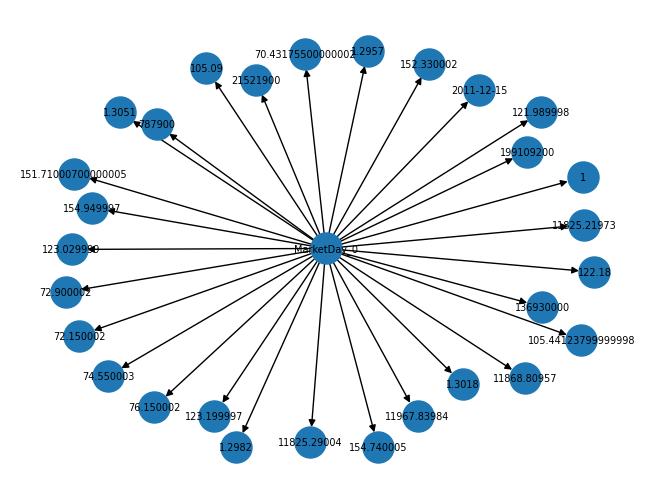

In [13]:
# 13 - visualize graph
sub_nodes = list(G.nodes)[:30]
nx.draw(G.subgraph(sub_nodes), with_labels=True, node_size=500, font_size=7)
plt.show()

In [14]:
# 14 - build tfidf index
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(knowledge_base["document"])

In [15]:
# 15 - retrieve documents
def retrieve_tfidf(query, k=3):
    query_vector = tfidf.transform([query])
    scores = cosine_similarity(query_vector, tfidf_matrix).flatten()
    indices = scores.argsort()[::-1][:k]
    return [(int(i), float(scores[i]), documents[i]) for i in indices]

In [16]:
# 16 - test retrieval
for record_id, score, document in retrieve_tfidf("gold closing price and stock market", 3):
    print(f"ID: {record_id} | Score: {score:.4f}\n{document}\n")

ID: 1716 | Score: 0.0187
Market data on 2018-12-28: Open 120.800003, High 121.080002, Low 120.720001, Close 121.059998, Adj Close 121.059998, Volume 6864700, SP_open 249.580002, SP_high 251.399994, SP_low 246.449997, SP_close 247.75, SP_Ajclose 247.75, SP_volume 153100200, DJ_open 23213.60938, DJ_high 23381.88086, DJ_low 22981.33008, DJ_close 23062.40039, DJ_Ajclose 23062.40039, DJ_volume 336510000, EG_open 2.85, EG_high 2.95, EG_low 2.85, EG_close 2.9, EG_Ajclose 2.9, EG_volume 1061100, EU_Price 1.1438, EU_open 1.1429, EU_high 1.1478, EU_low 1.1424, EU_Trend 1, OF_Price 52.2, OF_Open 53.44, OF_High 53.8, OF_Low 51.6, OF_Volume 17110, OF_Trend 1, OS_Price 44.92, OS_Open 45.23, OS_High 46.02, OS_Low 44.27, OS_Trend 0, SF_Price 38706, SF_Open 38749, SF_High 38880, SF_Low 38587, SF_Volume 14200, SF_Trend 1, USB_Price 2.716, USB_Open 2.768, USB_High 2.781, USB_Low 2.713, USB_Trend 0, PLT_Price 790.25, PLT_Open 795.6, PLT_High 800.5, PLT_Low 787.75, PLT_Trend 0, PLD_Price 1185.2, PLD_Open 1

In [17]:
# 18 - create embeddings
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(documents, show_progress_bar=True, normalize_embeddings=True)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/54 [00:00<?, ?it/s]

In [18]:
# 19 - semantic retrieval
def retrieve_semantic(query, k=3):
    query_embedding = embedding_model.encode([query], normalize_embeddings=True)
    scores = embeddings @ query_embedding[0]
    indices = scores.argsort()[::-1][:k]
    return [(int(i), float(scores[i]), documents[i]) for i in indices]

In [19]:
# 20 - test semantic retrieval
for record_id, score, document in retrieve_semantic("How did gold and stock market indicators behave?", 3):
    print(f"ID: {record_id} | Similarity: {score:.4f}\n{document}\n")

ID: 690 | Similarity: 0.3569
Market data on 2014-11-12: Open 112.050003, High 112.169998, Low 111.230003, Close 111.5, Adj Close 111.5, Volume 5133300, SP_open 203.350006, SP_high 204.240005, SP_low 203.309998, SP_close 203.960007, SP_Ajclose 187.293091, SP_volume 90120300, DJ_open 17604.75, DJ_high 17626.71094, DJ_low 17536.16992, DJ_close 17612.19922, DJ_Ajclose 17612.19922, DJ_volume 75980000, EG_open 29.25, EG_high 30.1, EG_low 28.200001, EG_close 28.75, EG_Ajclose 28.503717, EG_volume 1263300, EU_Price 1.2439, EU_open 1.2476, EU_high 1.2499, EU_low 1.2418, EU_Trend 0, OF_Price 80.38, OF_Open 81.25, OF_High 81.65, OF_Low 79.72, OF_Volume 116120, OF_Trend 0, OS_Price 76.89, OS_Open 77.64, OS_High 78.22, OS_Low 76.77, OS_Trend 0, SF_Price 34695, SF_Open 34758, SF_High 34955, SF_Low 34514, SF_Volume 21020, SF_Trend 0, USB_Price 2.373, USB_Open 2.373, USB_High 2.377, USB_Low 2.319, USB_Trend 1, PLT_Price 1199.65, PLT_Open 1201.4, PLT_High 1211.3, PLT_Low 1197.65, PLT_Trend 0, PLD_Price

In [20]:
# 21 - graph retrieval
def retrieve_graph(attribute, value):
    return [
        (subject, relation, obj)
        for subject, relation, obj in triples
        if relation == attribute and obj.lower() == str(value).lower()
    ]

In [21]:
# 22 - hybrid retrieval
def hybrid_retrieve(query, attribute=None, value=None, k=3):
    semantic_results = retrieve_semantic(query, k)
    graph_results = retrieve_graph(attribute, value) if attribute else []
    return {"documents": semantic_results, "triples": graph_results[:k]}

In [22]:
# 23 - test hybrid retrieval
results = hybrid_retrieve(
    "gold closing price",
    attribute="has_close",
    value=str(df.iloc[-1]["Close"]),
    k=3
)
print("Retrieved documents:")
for item in results["documents"]:
    print(item)
print("\nRetrieved graph triples:")
print(results["triples"])

Retrieved documents:
(618, 0.426052063703537, 'Market data on 2014-07-29: Open 125.790001, High 125.879997, Low 124.720001, Close 125.199997, Adj Close 125.199997, Volume 5267700, SP_open 198.169998, SP_high 198.449997, SP_low 196.919998, SP_close 196.949997, SP_Ajclose 180.014328, SP_volume 80466000, DJ_open 16984.33008, DJ_high 17056.46094, DJ_low 16912.10938, DJ_close 16912.10938, DJ_Ajclose 16912.10938, DJ_volume 75980000, EG_open 38.700001, EG_high 38.849998, EG_low 37.950001, EG_close 38.200001, EG_Ajclose 37.832569, EG_volume 342400, EU_Price 1.341, EU_open 1.344, EU_high 1.3445, EU_low 1.3403, EU_Trend 0, OF_Price 107.72, OF_Open 107.46, OF_High 108.05, OF_Low 107.13, OF_Volume 176640, OF_Trend 1, OS_Price 100.97, OS_Open 101.69, OS_High 101.92, OS_Low 100.47, OS_Trend 0, SF_Price 44269, SF_Open 44330, SF_High 44650, SF_Low 44140, SF_Volume 10620, SF_Trend 1, USB_Price 2.462, USB_Open 2.491, USB_High 2.498, USB_Low 2.451, USB_Trend 0, PLT_Price 1484.65, PLT_Open 1491.05, PLT_Hi

In [23]:
# 24 - test questions
test_questions = [
    "What was the gold opening price?",
    "What was the gold closing price?",
    "What was the highest gold price?",
    "What was the lowest gold price?",
    "What was the trading volume?",
    "How did the S&P 500 close?",
    "How did the Dow Jones close?",
    "What was the USD Index price?",
    "What was the oil price?",
    "How did gold and other market indicators change over time?"
]

In [24]:
# 25 - evaluate retrieval samples
for question in test_questions:
    print("\nQuestion:", question)
    for record_id, score, document in retrieve_semantic(question, 3):
        print(f"ID={record_id}, score={score:.3f}: {document}")


Question: What was the gold opening price?
ID=692, score=0.439: Market data on 2014-11-14: Open 110.760002, High 114.720001, Low 110.650002, Close 114.470001, Adj Close 114.470001, Volume 14173600, SP_open 204.100006, SP_high 204.490005, SP_low 203.720001, SP_close 204.240005, SP_Ajclose 187.550232, SP_volume 80417500, DJ_open 17653.10938, DJ_high 17664.15039, DJ_low 17613.19922, DJ_close 17634.74023, DJ_Ajclose 17634.74023, DJ_volume 72850000, EG_open 28.25, EG_high 31.200001, EG_low 27.85, EG_close 31.0, EG_Ajclose 30.734440000000006, EG_volume 1677700, EU_Price 1.2523, EU_open 1.2477, EU_high 1.2548, EU_low 1.2399, EU_Trend 1, OF_Price 79.41, OF_Open 77.67, OF_High 79.75, OF_Low 76.76, OF_Volume 267610, OF_Trend 1, OS_Price 75.96, OS_Open 74.49, OS_High 76.43, OS_Low 73.38, OS_Trend 1, SF_Price 36032, SF_Open 34568, SF_High 36266, SF_Low 33938, SF_Volume 50600, SF_Trend 1, USB_Price 2.319, USB_Open 2.345, USB_High 2.377, USB_Low 2.315, USB_Trend 0, PLT_Price 1213.7, PLT_Open 1196.2